In [1]:
from easymlops.automl.llms import SparkLLM,OllamaLLM,KimiLLM,ZhiPuLLM
from easymlops.automl.core import AutoML

### 1.训练

In [2]:
import numpy as np
def accuracy(y_true,y_pred):
    y_pred_label=np.where(y_pred>0.5,1,0)
    return np.mean(y_true==y_pred_label)

In [3]:
automl = AutoML(trn_path="./data/demo_trn.csv",
                val_path="./data/demo_val.csv",
                label="Survived",
                task_type="regression",
                llm_models=[SparkLLM(model="lite"),ZhiPuLLM(model="glm-4-9b")],
                llm_weights=[0.8,0.2],
                eval_metric=accuracy,eval_metric_direct="maximize",
                max_iter=50,early_stop_steps=20,
                max_time=2*60*60,
                parallel=5,agg_type="lightgbm_stacking")
automl.fit()

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

In [5]:
automl[2]

### 2.评估

In [6]:
import pandas as pd
import numpy as np

In [7]:
oot_df=pd.read_csv("./data/demo_oot.csv")
oot_df["pred"]=automl.transform(oot_df)
print("all",np.sum(oot_df["Survived"]==oot_df["pred"].apply(lambda x:1 if x>0.5 else 0))/len(oot_df))

for idx in range(5):
    oot_df=pd.read_csv("./data/demo_oot.csv")
    oot_df["pred"]=automl[idx].transform(oot_df)
    print(idx,np.sum(oot_df["Survived"]==oot_df["pred"].apply(lambda x:1 if x>0.5 else 0))/len(oot_df))

all 0.8324607329842932
0 0.837696335078534
1 0.8272251308900523
2 0.837696335078534
3 0.8167539267015707
4 0.7905759162303665


In [8]:
automl[4].main_pipeline.models

### 3.eval_metric值变化

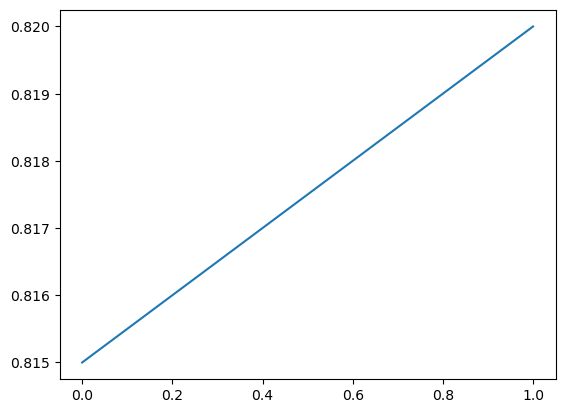

In [9]:
automl[4].llm_session_manager.plot_val_loss_in_queue(-1)

### 4.会话追踪

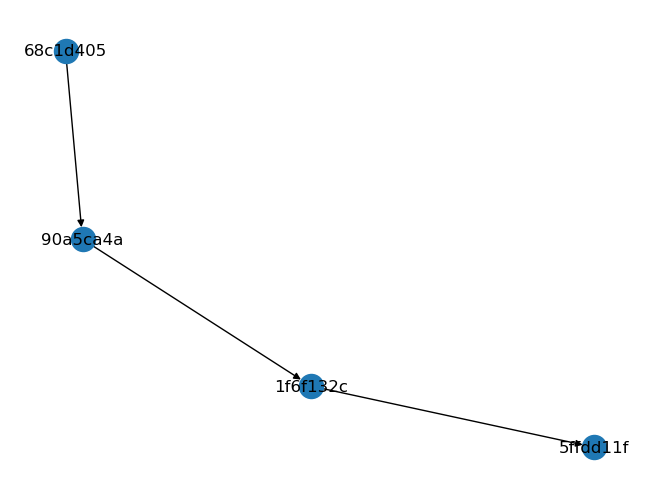

In [10]:
automl[0].llm_session_manager.plot_dag_state()

In [13]:
automl[0].llm_session_manager.get_state("1f6f132c").keys()

dict_keys(['tools_count', 'trn_evaluate_value', 'val_evaluate_value', 'history_messages', 'main_pipeline', 'operator', 'call_status', 'tools', 'call_models', 'msg', 'tool', 'tool_param'])

#### 查看对话流水

In [14]:
automl[2].llm_session_manager.queue[:5]

['a3aa76cc', '4574d5e8', '5537f20c', '88272d4f', '8023cea6']

In [15]:
print(automl[2].llm_session_manager.get_state("5537f20c")["history_messages"][-2]["content"])


                   you chose the tool:fasttext,the describe as follow:

                   {'tool': 'fasttext', 'describe': 'f"""fasttext模型,用于增强文本特征(sample中绝大多数为非数值型)的表达能力,该tool需要优先使用,入参默认值及其解释,见parameters,你需要返回如{"cols":["col1","col2"],"embedding_size":16,"min_count":5}这样的参数形式"""', 'parameters': {'type': 'object', 'properties': {'cols': {'default': 'all', 'type': 'list', 'describe': '默认为"all",表示处理所有特征,但文本特征(sample中绝大多数为非数值型)通常只有少数,用list格式["col1","col2"],只对col1和col2文本特征建模'}, 'embedding_size': {'default': 16, 'type': 'int', 'describe': '默认为16,表示embedding的维度'}, 'min_count': {'default': 5, 'type': 'int', 'describe': '默认为5,表示窗口长度'}}, 'required': ['cols']}}

                   now the feature representation  as follow:
                    [{'col': 'PassengerId', 'type': dtype('uint16'), 'type_describe': '数值型', 'missing': '0.00%', 'unique': 500, 'unique_rate': 1.0, 'sample': '342:0.20%;341:0.20%;162:0.20%;160:0.20%;159:0.20%'}, {'col': 'Pclass', 'type': dtype('uint8'), 'type_describe': '数值型'

In [16]:
print(automl[2].llm_session_manager.get_state("5537f20c")["history_messages"][-1]["content"])

```Parameters: {"cols": ["PassengerId", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"], "embedding_size": 16, "min_count": 5}```


In [17]:
print(automl[9].llm_session_manager.get_state("83cd7f62")["history_messages"][-2]["content"])


                   you chose the tool:auto_residual_regression,the describe as follow:

                   {'tool': 'auto_residual_regression', 'describe': 'f"""对预测目标做残差版预测,用于增强特征表达能力,入参默认值及其解释,见parameters,你需要返回如{"layers":3}这样的参数形式"""', 'parameters': {'type': 'object', 'properties': {'layers': {'type': 'int', 'describe': '需要构建残差结构的层数,默认为3'}}, 'required': ['layers']}}

                   now the feature representation  as follow:
                    [{'col': 'PassengerId', 'type': dtype('uint16'), 'type_describe': '数值型', 'missing': '0.00%', 'unique': 500, 'unique_rate': 1.0, 'sample': '342:0.20%;341:0.20%;162:0.20%;160:0.20%;159:0.20%'}, {'col': 'Pclass', 'type': dtype('uint8'), 'type_describe': '数值型', 'missing': '0.00%', 'unique': 3, 'unique_rate': 0.006, 'sample': 'None;None;None;3:55.80%;1:23.20%'}, {'col': 'Name', 'type': dtype('O'), 'type_describe': '离散型', 'missing': '0.00%', 'unique': 500, 'unique_rate': 1.0, 'sample': 'Fortune, Miss. Alice Elizabeth:0.20%;Navratil, Master. Edmon

In [18]:
print(automl[9].llm_session_manager.get_state("83cd7f62")["history_messages"][-1]["content"])

```Parameters: {"layers":3}```


### 5.保存&加载

In [17]:
# automl.save("automl_config")

In [18]:
# automl=AutoML()
# automl.load("automl_config")

In [19]:
# import pandas as pd
# oot_df=pd.read_csv("./data/demo_oot.csv")
# oot_df["pred"]=automl.transform(oot_df)

In [20]:
# import numpy as np
# np.sum(oot_df["Survived"]==oot_df["pred"].apply(lambda x:1 if x>0.5 else 0))/len(oot_df)

### 6.TODO

#### 算法

beam search;优化流程(添加对loss的解析);添加知识库;有监督微调(特征描述+工具+任务类型=>loss变化)...

#### 工程
prompt自定义;loss function自定义;tools自定义...

In [19]:
def my_function(a,b):
    return a-b

In [22]:
a=1
b=2
eval("my_function(a,b)")

-1